In [27]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import NullFormatter
import pickle as pk
%matplotlib inline


In [28]:

with (open("../model1_dissipative/results/imps_analytic_prediction_summary_data.pkl", "rb")) as openfile:
    data = pk.load(openfile)
        

In [29]:
inf_values_data = data["inf_values"]
inf_values = list(inf_values_data.values())
inf_values_ar = np.zeros((4,10))
for i in range(4):
    for j in range(10):
        inf_values_ar[i,j]=inf_values[i*j]
inf_values_ar[:,2]
analytics=np.array(data["q_at"][0.2])/(0.2**2)

In [30]:
finite_values_data = data["finite_values"]
finite_values_data



{(0, 4): 0.0007099018045422939,
 (0, 8): 0.0007109345169920314,
 (0, 12): 0.000712684813853316,
 (0, 16): 0.000713138119244137,
 (0, 20): 0.0006944489692493819,
 (1, 4): 0.001302574017680238,
 (1, 8): 0.0013059248173555623,
 (1, 12): 0.001313858830659757,
 (1, 16): 0.0013396900840307122,
 (1, 20): 0.0012666986991341053,
 (2, 4): 0.0007006746562723482,
 (2, 8): 0.0007015241064916799,
 (2, 12): 0.0007031605211027239,
 (2, 16): 0.0007120403175114281,
 (2, 20): 0.000767700490188409,
 (3, 4): 0.0009888659206536894,
 (3, 8): 0.000990858862165128,
 (3, 12): 0.000994459930353028,
 (3, 16): 0.000998322063263032,
 (3, 20): 0.0010090809430809819,
 (4, 4): 0.000653627921344242,
 (4, 8): 0.0006545257278940328,
 (4, 12): 0.0006557697548875234,
 (4, 16): 0.0006646370648341791,
 (4, 20): 0.0006474901376872425,
 (5, 4): 0.0017827589862564402,
 (5, 8): 0.0017892534692524034,
 (5, 12): 0.0017997947141985325,
 (5, 16): 0.0018191999866237684,
 (5, 20): 0.0017941905603745657,
 (6, 4): 0.002772222642772993,


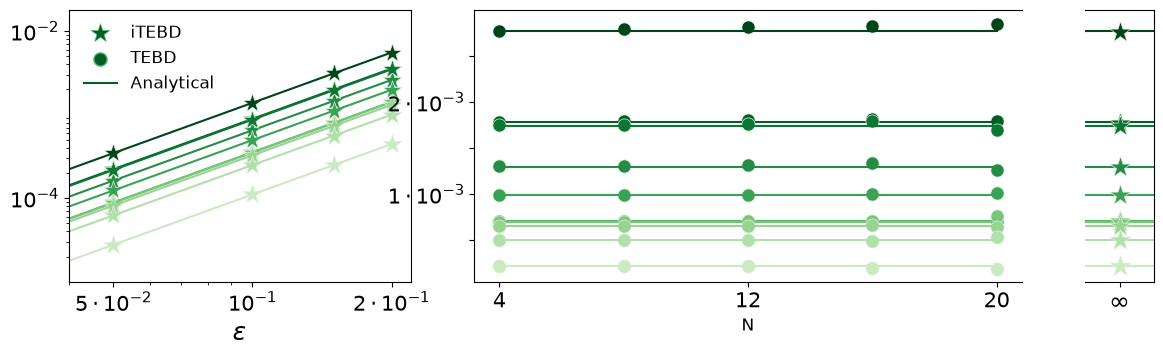

In [31]:
fig, ax = plt.subplots(1,3, figsize = (14,4),gridspec_kw={"width_ratios": [1, 1.6,0.2]})
colors = plt.get_cmap("Greens")(np.linspace(0.15, 1.0, 11))
sorting =  np.argsort(np.argsort(analytics))
x_values = sorted({key[0] for key in inf_values_data})
epsilon = np.linspace(0,0.2,300)
for i in range(10):
    ax[0].scatter(x_values, [inf_values_data[(x, i)] for x in x_values],
             marker="*", color = colors[1+sorting[i]],edgecolor=colors[0], linewidth = 0.5, s = 200)
    ax[0].plot(epsilon,epsilon**2*analytics[i]/4,color = colors[1+sorting[i]],zorder=1)


   #for legend
ax[0].scatter([0], 1000,
                 marker="*", color = colors[1+sorting[5]],edgecolor=colors[5], label = "iTEBD", linewidth = 0.5, s = 200)
ax[0].scatter([0], 1000,
                 marker="o", color = colors[1+sorting[5]],edgecolor=colors[5], label = "TEBD", linewidth = 1, s = 90)
ax[0].plot(epsilon,1000+epsilon,color = colors[1+sorting[5]],label = "Analytical",zorder=1)
    
ax[0].set_yscale("log")
ax[0].set_xscale("log")

ax[0].set_ylim(10**-5,1.8*10**-2)
ax[0].legend(fontsize = 12, frameon = False)
ax[0].set_yticks([1e-4,1e-2])
ax[0].set_yticklabels([r"$10^{-4}$",r"$10^{-2}$"], fontsize =15)


ax[0].set_xticks([5e-2,1e-1,2e-1])
ax[0].set_xticklabels([r"$5\cdot 10^{-2}$",r"$10^{-1}$",r"$2\cdot 10^{-1}$"],fontsize = 15)
ax[0].xaxis.set_minor_formatter(NullFormatter())
ax[0].set_xlim(0.04,0.22)
ax[0].set_xlabel(r"$\epsilon$", fontsize = 18)

x_values = sorted({key[1] for key in finite_values_data})
sizes = [4,8,12,16,20]
for i in range(10):
    ax[1].scatter(sizes, [finite_values_data[(i, x)] for x in x_values],
             marker="o", color = colors[1+sorting[i]],edgecolor=colors[0], linewidth = 0.5, s = 90)
    ax[1].plot(sizes,0.2**2*analytics[i]/8*np.ones_like(sizes),color = colors[1+sorting[i]],zorder=1)

ax[1].spines["right"].set_visible(False)
ax[1].set_yticks([])
ax[1].set_xticks([4,12,20])
ax[1].set_xticklabels(["4","12","20"],fontsize = 15)
ax[1].set_xlabel("N", fontsize = 12)
ax[1].set_ylim(0.00005,0.003)
ax[1].tick_params(right=False, labelright=False, left=True, labelleft=True)
ax[1].set_yticks([0.0005,0.001,0.0015,0.002,0.0025])
ax[1].set_yticklabels(["",r"$1\cdot 10^{-3}$","",r"$2\cdot 10^{-3}$",""], fontsize = 15)


ax[2].tick_params(right=True, labelright=True, left=False, labelleft=False)
ax[2].set_yticks([])
ax[2].set_yticklabels([], fontsize = 15)


ax[2].set_xlim(-0.5, 0.5)
ax[2].set_xticks([0])
ax[2].spines["left"].set_visible(False)
ax[2].set_xticklabels([r"$\infty$"],fontsize = 18)
ax[2].set_ylim(0.00005,0.003)

inf_x=np.array([-0.5,0.5])
for i in range(10):
    ax[2].plot(inf_x,0.2**2*analytics[i]/8*np.ones_like(inf_x),color = colors[1+sorting[i]],zorder=1)

for i in range(10):
    ax[2].scatter([0],[0.5*inf_values_data[(0.2, i)]],marker="*", color = colors[1+sorting[i]],edgecolor=colors[0], linewidth = 0.5, s = 250)

out_path = "figure_paper.pdf"
fig.subplots_adjust(bottom=0.2)
fig.savefig(out_path, format = "pdf")





In [32]:
with (open("../model3_hamiltonian/results/ham_finite_size_table.pkl", "rb")) as openfile:
    data_ham = pk.load(openfile)
        

In [33]:
data_ham

{'records': [{'method': 'exact',
   'kind': 'grid',
   'N': 4,
   'epsilon': 0.2,
   'sample': 0,
   'chi_max': None,
   'init': None,
   'correlator': 0.0006685584163345151,
   'c2': 0.028961918712972184,
   'R_over_c2': 0.02308405126608772,
   'stage_drift': None,
   'max_bond': None,
   'bond_at_cap': None,
   'max_discarded_weight': None,
   'residual': None,
   'min_profile': None,
   'gap_rate': 3.06333552437166,
   'purity': 0.9975095930615882,
   'seconds': None,
   'source': 'ham_finite_size.pkl',
   'supersedes_ok': True},
  {'method': 'exact',
   'kind': 'grid',
   'N': 4,
   'epsilon': 0.2,
   'sample': 1,
   'chi_max': None,
   'init': None,
   'correlator': 0.0001834505136977328,
   'c2': 0.007946266943240465,
   'R_over_c2': 0.02308637691234196,
   'stage_drift': None,
   'max_bond': None,
   'bond_at_cap': None,
   'max_discarded_weight': None,
   'residual': None,
   'min_profile': None,
   'gap_rate': 3.0582869174371927,
   'purity': 0.9993154790833528,
   'seconds': 

In [34]:
result_ham = np.array(
    [
        [r["N"], r["sample"], r["correlator"], r["epsilon"]]
        for r in data_ham["records"]
        if r["method"] == "tebd"
        and r["init"] == "zero"
        and r["N"] < 14
        and r["sample"] not in (None, "None")
    ],
    dtype=float,
).reshape(-1, 4)

records = [
    r for r in data_ham["records"]
    if r["method"] == "tebd"
    and r["init"] == "zero"
    and r["N"] < 14
    and r["sample"] not in (None, "None")
]

array_N12 = np.array(
    [[r["sample"], r["epsilon"], r["correlator"]]
     for r in records if r["N"] == 12],
    dtype=float,
).reshape(-1, 3)

array_eps02 = np.array(
    [[r["sample"], r["N"], r["correlator"]]
     for r in records if np.isclose(r["epsilon"], 0.2)],
    dtype=float,
).reshape(-1, 3)

In [35]:
array_eps02

array([[9.00000000e+00, 1.20000000e+01, 6.07622700e-04],
       [9.00000000e+00, 1.20000000e+01, 6.00898745e-04],
       [9.00000000e+00, 1.20000000e+01, 5.99587112e-04],
       [0.00000000e+00, 4.00000000e+00, 6.68645436e-04],
       [1.00000000e+00, 4.00000000e+00, 1.83474426e-04],
       [2.00000000e+00, 4.00000000e+00, 2.24062574e-04],
       [3.00000000e+00, 4.00000000e+00, 2.39476869e-04],
       [4.00000000e+00, 4.00000000e+00, 4.94661654e-05],
       [5.00000000e+00, 4.00000000e+00, 7.61724272e-05],
       [6.00000000e+00, 4.00000000e+00, 3.55807733e-04],
       [7.00000000e+00, 4.00000000e+00, 5.95070882e-04],
       [8.00000000e+00, 4.00000000e+00, 4.15191314e-04],
       [9.00000000e+00, 4.00000000e+00, 6.52497372e-04],
       [0.00000000e+00, 6.00000000e+00, 6.25016900e-04],
       [1.00000000e+00, 6.00000000e+00, 1.71529518e-04],
       [2.00000000e+00, 6.00000000e+00, 2.09450993e-04],
       [3.00000000e+00, 6.00000000e+00, 2.23895907e-04],
       [4.00000000e+00, 6.00000

[0.00066865 0.00062502 0.00061604 0.00061921 0.00061325]
[0.00018347 0.00017153 0.00016897 0.00016972 0.00016826]
[0.00022406 0.00020945 0.00020635 0.00021014 0.00020558]
[0.00023948 0.0002239  0.0002206  0.00022297 0.0002192 ]
[4.94661654e-05 4.62627800e-05 4.55748180e-05 4.79631355e-05
 4.48200132e-05]
[7.61724272e-05 7.12094851e-05 7.01542502e-05 7.34465133e-05
 6.89497985e-05]
[0.00035581 0.00033248 0.00032749 0.00033324 0.00032682]
[0.00059507 0.00055641 0.00054832 0.0005532  0.00054485]
[0.00041519 0.00038824 0.00038257 0.00038809 0.00038099]
[0.00060762 0.0006009  0.00059959 0.0006525  0.00061018 0.00060158
 0.00060762 0.00059959]


C:\Users\nzier\AppData\Local\Temp\ipykernel_26076\3251446318.py:31: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax[0].legend(fontsize = 12, frameon = False)


ValueError: The number of FixedLocator locations (0), usually from a call to set_ticks, does not match the number of labels (5).

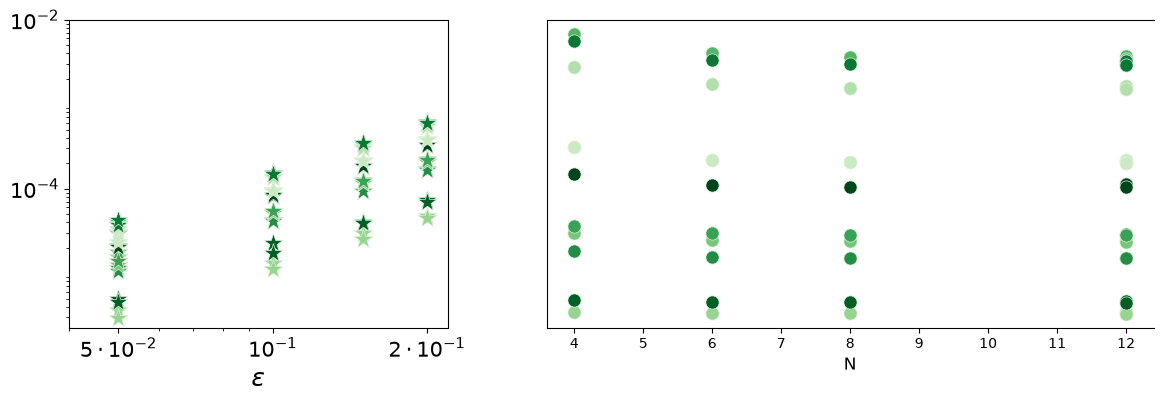

In [36]:
fig, ax = plt.subplots(1,2, figsize = (14,4),gridspec_kw={"width_ratios": [1, 1.6]})
colors = plt.get_cmap("Greens")(np.linspace(0.15, 1.0, 11))
sorting =  np.argsort(np.argsort(analytics))
x_values = [0.05,0.1,0.15,0.2]
epsilon = np.linspace(0,0.2,300)

for i in range(10):
    rows = array_N12[array_N12[:, 0] == i]
    rows = rows[np.argsort(rows[:, 1])]  # Sort by epsilon
    ax[0].scatter(rows[:,1], rows[:,2],marker="*", color = colors[1+sorting[i]],edgecolor=colors[0], linewidth = 0.5, s = 200)
    


#for i in range(10):
 #   ax[0].scatter(x_values, [inf_values_data[(x, i)] for x in x_values],
  #           marker="*", color = colors[1+sorting[i]],edgecolor=colors[0], linewidth = 0.5, s = 200)
   # ax[0].plot(epsilon,epsilon**2*analytics[i]/4,color = colors[1+sorting[i]],zorder=1)


   #for legend
#ax[0].scatter([0], 1000,
              #   marker="*", color = colors[1+sorting[5]],edgecolor=colors[5], label = "iTEBD", linewidth = 0.5, s = 200)
#ax[0].scatter([0], 1000,
               #  marker="o", color = colors[1+sorting[5]],edgecolor=colors[5], label = "TEBD", linewidth = 1, s = 90)
#ax[0].plot(epsilon,1000+epsilon,color = colors[1+sorting[5]],label = "Analytical",zorder=1)
    
ax[0].set_yscale("log")
ax[0].set_xscale("log")

#ax[0].set_ylim(10**-5,1.8*10**-2)
ax[0].legend(fontsize = 12, frameon = False)
ax[0].set_yticks([1e-4,1e-2])
ax[0].set_yticklabels([r"$10^{-4}$",r"$10^{-2}$"], fontsize =15)


ax[0].set_xticks([5e-2,1e-1,2e-1])
ax[0].set_xticklabels([r"$5\cdot 10^{-2}$",r"$10^{-1}$",r"$2\cdot 10^{-1}$"],fontsize = 15)
ax[0].xaxis.set_minor_formatter(NullFormatter())
ax[0].set_xlim(0.04,0.22)
ax[0].set_xlabel(r"$\epsilon$", fontsize = 18)

x_values = sorted({key[1] for key in finite_values_data})
sizes = [4,6,8,10,12]
for i in range(10):
    rows = array_eps02[array_eps02[:,0]==i]
    print(rows[:,2])
    ax[1].scatter(rows[:,1], rows[:,2],
             marker="o", color = colors[1+sorting[i]],edgecolor=colors[0], linewidth = 0.5, s = 90)
    #ax[1].plot(sizes,0.2**2*analytics[i]/8*np.ones_like(sizes),color = colors[1+sorting[i]],zorder=1)

ax[1].spines["right"].set_visible(False)
ax[1].set_yticks([])
#ax[1].set_xticks([4,12,20])
#ax[1].set_xticklabels(["4","12","20"],fontsize = 15)
ax[1].set_xlabel("N", fontsize = 12)
#ax[1].set_ylim(0.00005,0.003)
#ax[1].tick_params(right=False, labelright=False, left=True, labelleft=True)
#ax[1].set_yticks([0.0005,0.001,0.0015,0.002,0.0025])
ax[1].set_yticklabels(["",r"$1\cdot 10^{-3}$","",r"$2\cdot 10^{-3}$",""], fontsize = 15)



out_path = "figure_paper.pdf"
fig.subplots_adjust(bottom=0.2)
#fig.savefig(out_path, format = "pdf")





[0.00066865 0.00062502 0.00061604 0.00061921 0.00061325]
[0.00018347 0.00017153 0.00016897 0.00016972 0.00016826]
[0.00022406 0.00020945 0.00020635 0.00021014 0.00020558]
[0.00023948 0.0002239  0.0002206  0.00022297 0.0002192 ]
[4.94661654e-05 4.62627800e-05 4.55748180e-05 4.79631355e-05
 4.48200132e-05]
[7.61724272e-05 7.12094851e-05 7.01542502e-05 7.34465133e-05
 6.89497985e-05]
[0.00035581 0.00033248 0.00032749 0.00033324 0.00032682]
[0.00059507 0.00055641 0.00054832 0.0005532  0.00054485]
[0.00041519 0.00038824 0.00038257 0.00038809 0.00038099]
[0.0006525  0.00061018 0.00060158 0.00060762 0.00059959 0.0006009
 0.00060762 0.00059959]


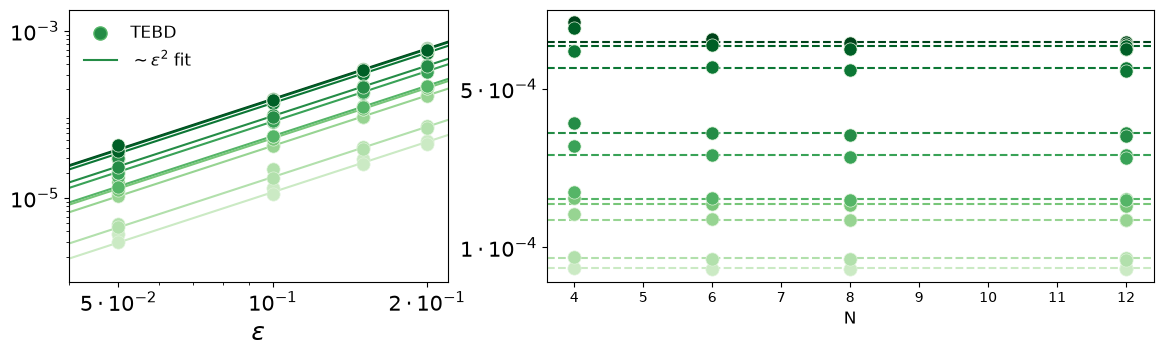

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import NullFormatter

fig, ax = plt.subplots(
    1, 2, figsize=(14, 4),
    gridspec_kw={"width_ratios": [1, 1.6]}
)
colors = plt.get_cmap("Greens")(np.linspace(0.15, 1.0, 11))


def rank_samples(data):
    samples = np.unique(data[:, 0])

    def rightmost_value(sample):
        rows = data[data[:, 0] == sample]
        return rows[np.argmax(rows[:, 1]), 2]

    return {
        sample: rank
        for rank, sample in enumerate(sorted(samples, key=rightmost_value))
    }


sorting_N12 = rank_samples(array_N12)
sorting_eps02 = rank_samples(array_eps02)

x_values = [0.05, 0.1, 0.15, 0.2]
epsilon = np.linspace(0, 0.2, 300)

sorting = sorting_N12
fit_coefficients = {}

for i in range(10):
    rows = array_N12[array_N12[:, 0] == i]
    rows = rows[np.argsort(rows[:, 1])]  # Sort by epsilon
    color = colors[1 + sorting[i]]

    ax[0].scatter(
        rows[:, 1], rows[:, 2],
        marker="o", color=color,
        edgecolor=colors[0], linewidth=0.5, s=90,
        zorder=3
    )

    # Least-squares fit: correlator = a * epsilon**2
    valid = np.isfinite(rows[:, 1]) & np.isfinite(rows[:, 2])
    x = rows[valid, 1]
    y = rows[valid, 2]

    if len(x) and np.any(x != 0):
        a = np.linalg.lstsq((x**2)[:, None], y, rcond=None)[0][0]
        fit_coefficients[i] = a

        # Positive epsilon values for the logarithmic axis
        epsilon_fit = np.linspace(0.04, 0.22, 300)
        ax[0].plot(
            epsilon_fit, a * epsilon_fit**2,
            color=color, linewidth=1.5, zorder=1
        )


#for i in range(10):
 #   ax[0].scatter(x_values, [inf_values_data[(x, i)] for x in x_values],
  #           marker="*", color = colors[1+sorting[i]],edgecolor=colors[0], linewidth = 0.5, s = 200)
   # ax[0].plot(epsilon,epsilon**2*analytics[i]/4,color = colors[1+sorting[i]],zorder=1)


 #  for legend
#ax[0].scatter([0], 1000,
 #               marker="*", color = colors[1+sorting[8]],edgecolor=colors[8], label = "iTEBD", linewidth = 0.5, s = 200)
ax[0].scatter([0], 1000,
                 marker="o", color = colors[1+sorting[8]],edgecolor=colors[5], label = "TEBD", linewidth = 1, s = 90)
ax[0].plot(epsilon,1000+epsilon,color = colors[1+sorting[8]],label = r"$\sim \epsilon^2$ fit",zorder=1)

ax[0].set_yscale("log")
ax[0].set_xscale("log")

ax[0].set_ylim(10**-6,1.8*10**-3)
handles, labels = ax[0].get_legend_handles_labels()
if handles:
    ax[0].legend(fontsize=12, frameon=False)

#ax[0].set_yticks([1e-4, 1e-2])
#ax[0].set_yticklabels([r"$10^{-4}$", r"$10^{-2}$"], fontsize=15)

ax[0].set_xticks([5e-2, 1e-1, 2e-1])
ax[0].set_xticklabels(
    [r"$5\cdot 10^{-2}$", r"$10^{-1}$", r"$2\cdot 10^{-1}$"],
    fontsize=15
)
ax[0].xaxis.set_minor_formatter(NullFormatter())
ax[0].set_xlim(0.04, 0.22)
ax[0].set_xlabel(r"$\epsilon$", fontsize=18)

x_values = sorted(np.unique(array_eps02[:, 1]))
sizes = [4, 6, 8, 10, 12]

sorting = sorting_eps02

for i in range(10):
    rows = array_eps02[array_eps02[:, 0] == i]
    rows = rows[np.argsort(rows[:, 1])]
    color = colors[1 + sorting[i]]

    print(rows[:, 2])
    ax[1].scatter(
        rows[:, 1], rows[:, 2],
        marker="o", color=color,
        edgecolor=colors[0], linewidth=0.5, s=90,
        zorder=3
    )
    #ax[1].plot(sizes,0.2**2*analytics[i]/8*np.ones_like(sizes),color = colors[1+sorting[i]],zorder=1)

    # Horizontal reference at this sample's N = 12 value
    rows_N12 = rows[rows[:, 1] == 12]
    if len(rows_N12):
        ax[1].axhline(
            y=rows_N12[0, 2],
            color=color, linestyle="--", linewidth=1.5,
            zorder=1
        )

#ax[1].set_yticks([])
ax[1].set_yticks([1e-4,5e-4])
ax[0].set_yticks([10e-6,10e-4])
ax[1].set_yticklabels([r"$1\cdot 10^{-4}$",r"$5\cdot 10^{-4}$"],fontsize = 15)
ax[0].set_yticklabels([r"$10^{-5}$",r"$10^{-3}$"],fontsize = 15)

ax[1].set_xlabel("N", fontsize=12)
#ax[1].set_ylim(0.00005,0.003)
#ax[1].tick_params(right=False, labelright=False, left=True, labelleft=True)
#ax[1].set_yticks([0.0005,0.001,0.0015,0.002,0.0025])
#ax[1].set_yticklabels(["",r"$1\cdot 10^{-3}$","",r"$2\cdot 10^{-3}$",""], fontsize = 15)

out_path = "figure_paper_hamiltonian.pdf"
fig.subplots_adjust(bottom=0.2)
fig.savefig(out_path, format = "pdf")

plt.show()

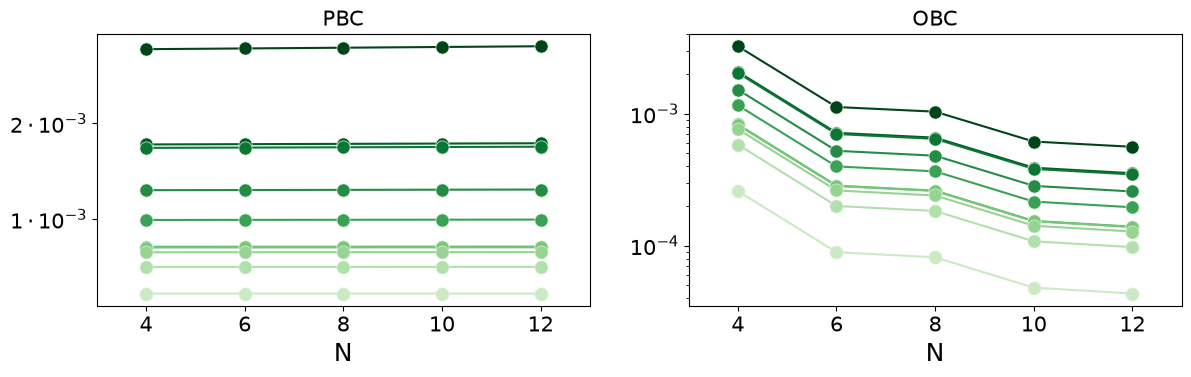

In [37]:
# Drift model (p = 0.8), eps = 0.05: exact finite-N steady states, ring (left) vs open chain (right)
with open("../model2_drift/results/drift_circuit_exact_finite_pbc.pkl", "rb") as openfile:
    data_drift_pbc = pk.load(openfile)
with open("../model2_drift/results/drift_circuit_exact_finite.pkl", "rb") as openfile:
    data_drift_obc = pk.load(openfile)

eps_drift = 0.05
sizes_drift = [4, 6, 8, 10, 12]
res_pbc = data_drift_pbc["results"]
res_obc = data_drift_obc["results"]
finite_pbc = np.array([[res_pbc[(0.8, eps_drift, s, N)]["R"] for N in sizes_drift]
                       for s in range(10)])
finite_obc = np.array([[res_obc[(0.8, eps_drift, s, N)]["R"] for N in sizes_drift]
                       for s in range(10)])
q_drift = np.array([res_pbc[(0.8, eps_drift, s, 4)]["q"] for s in range(10)])

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
colors = plt.get_cmap("Greens")(np.linspace(0.15, 1.0, 11))
sorting = np.argsort(np.argsort(q_drift))   # colour by pair-creation rate q

for i in range(10):
    color = colors[1 + sorting[i]]
    for a, values in ((ax[0], finite_pbc), (ax[1], finite_obc)):
        a.plot(sizes_drift, values[i], color=color, linewidth=1.5, zorder=1)
        a.scatter(sizes_drift, values[i], marker="o", color=color,
                  edgecolor=colors[0], linewidth=0.5, s=90, zorder=3)

ax[0].set_title("PBC", fontsize=15)
ax[1].set_title("OBC", fontsize=15)

ax[0].set_yticks([1e-3, 2e-3])
ax[0].set_yticklabels([r"$1\cdot 10^{-3}$", r"$2\cdot 10^{-3}$"], fontsize=15)

ax[1].set_yscale("log")
ax[1].set_yticks([1e-4, 1e-3])
ax[1].set_yticklabels([r"$10^{-4}$", r"$10^{-3}$"], fontsize=15)
ax[1].yaxis.set_minor_formatter(NullFormatter())

for a in ax:
    a.set_xlim(3, 13)
    a.set_xticks(sizes_drift)
    a.set_xticklabels([str(N) for N in sizes_drift], fontsize=15)
    a.set_xlabel("N", fontsize=18)

out_path = "figure_paper_drift.pdf"
fig.subplots_adjust(bottom=0.2)
fig.savefig(out_path, format="pdf")
plt.show()